In [1]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

In [2]:
df = pd.read_csv('PoliticalDemocracy.csv')
var_names = df.columns.values.tolist()
dataset = torch.tensor(df.to_numpy()).to(dtype = torch.float32)
batch_size = 25
dataloader = DataLoader(TensorDataset(dataset), batch_size = batch_size, shuffle = True)

In [3]:
observation = next(iter(dataloader))
print(observation)

[tensor([[ 9.2000,  0.0000,  9.9000,  3.3333,  7.6097,  0.0000,  8.1188,  3.3333,
          4.3820,  2.8904,  1.7113],
        [ 2.5000,  0.0000,  6.6667,  3.3333,  2.5000,  0.0000,  0.0000,  0.0000,
          3.8067,  2.0794,  2.1376],
        [ 2.5000,  0.0000,  6.6667,  4.4333,  5.0000,  0.0000,  6.6667,  1.4852,
          5.0752,  5.2523,  5.3507],
        [ 3.3000,  0.0000,  6.6667,  3.3333,  6.2500,  0.0000,  6.6667,  3.3333,
          5.1417,  4.5643,  2.2551],
        [ 7.8000, 10.0000,  6.6667,  6.6667,  5.0000,  3.3333,  6.6667,  6.6667,
          5.0499,  5.1120,  4.3815],
        [ 5.0000,  3.3333,  3.3333,  2.2333,  5.0000,  3.3333,  6.6667,  5.5667,
          5.2575,  5.8406,  5.0018],
        [ 1.2500,  0.0000,  4.7000,  0.7370,  2.5000,  0.0000,  3.3333,  3.3333,
          4.8598,  5.6699,  3.5374],
        [ 7.5000,  3.3333,  6.6667,  6.6667,  8.7500,  3.3333,  6.6667,  6.6667,
          5.3982,  6.2461,  4.5357],
        [ 2.5000,  0.0000,  3.3333,  3.3333,  2.5000,  

In [4]:
print(var_names)

['y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'x1', 'x2', 'x3']


In [5]:
from torch import nn

In [6]:
tmp = [nn.Linear(1 + 1, 1) for i in range(3)]
tmp[0] is tmp[1]

False

In [7]:
class LinearFactor(nn.Module):    
    """Modified from engression.models.StoLayer.

    Args:
        in_dim (int): input dimension 
        out_dim (int): output dimension
    """
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.in_dim = in_dim
        self.out_dim = out_dim     
        self.layers = nn.ModuleList([nn.Linear(in_dim + 1, 1) for i in range(out_dim)])
    
    def forward(self, x):
        # device = next(self.layer.parameters()).device
        if x.size(1) != self.in_dim:
            raise ValueError("Input dimension does not match.")
        else:
            eps = torch.randn(x.size(0), self.out_dim)
            x = torch.cat([self.layers[i](torch.cat((x, eps[:,i,None]), 1)) 
                           for i in range(self.out_dim)], 1)
        return x

In [8]:
x = dataset[:, -3:]
n = x.size(0)
print(n)

75


In [9]:
from engression.loss_func import energy_loss_two_sample
model = LinearFactor(1, 3)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for i in range(1000):
    optimizer.zero_grad()
    z1 = torch.randn(n, 1)    
    z2 = torch.randn(n, 1)
    sample1 = model(z1)
    sample2 = model(z2)
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 7.1823, s1: 7.9941, s2: 1.6235
Iter 100 | loss: 4.7940, s1: 6.8736, s2: 4.1594
Iter 200 | loss: 3.8453, s1: 6.5091, s2: 5.3276
Iter 300 | loss: 2.5794, s1: 5.4706, s2: 5.7824
Iter 400 | loss: 2.0618, s1: 4.5930, s2: 5.0624
Iter 500 | loss: 1.7353, s1: 3.8055, s2: 4.1403
Iter 600 | loss: 1.6248, s1: 3.3930, s2: 3.5363
Iter 700 | loss: 1.2333, s1: 2.7180, s2: 2.9693
Iter 800 | loss: 1.3381, s1: 2.5363, s2: 2.3963
Iter 900 | loss: 1.4290, s1: 2.8798, s2: 2.9016
Iter 1000 | loss: 1.2642, s1: 2.6604, s2: 2.7925


In [10]:
[model.layers[i].weight for i in range(3)]

[Parameter containing:
 tensor([[-0.6773, -0.3532]], requires_grad=True),
 Parameter containing:
 tensor([[-1.4330,  0.4968]], requires_grad=True),
 Parameter containing:
 tensor([[-1.3765, -0.5638]], requires_grad=True)]

In [11]:
beta = [model.layers[i].weight[0][0].detach().numpy().tolist() for i in range(3)]

In [12]:
[beta[i] / beta[0] for i in range(3)]

[1.0, 2.1158674268503073, 2.032429812193289]

In [13]:
z = torch.randn(n * 100, 1)    
sample = model(z)
sample_df = pd.DataFrame(sample.detach().numpy(), columns = ["x1", "x2", "x3"])

<Axes: ylabel='Frequency'>

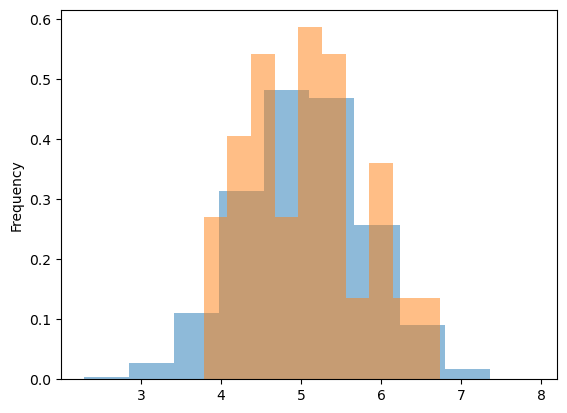

In [14]:
sample_df["x1"].plot.hist(alpha = 0.5, density = True)
df["x1"].plot.hist(alpha = 0.5, density = True)

<Axes: ylabel='Frequency'>

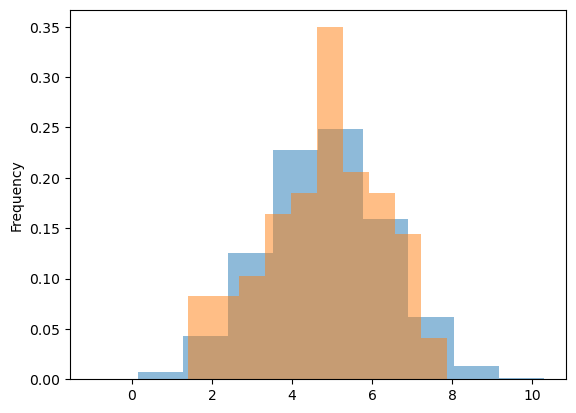

In [15]:
sample_df["x2"].plot.hist(alpha = 0.5, density = True)
df["x2"].plot.hist(alpha = 0.5, density = True)

<Axes: ylabel='Frequency'>

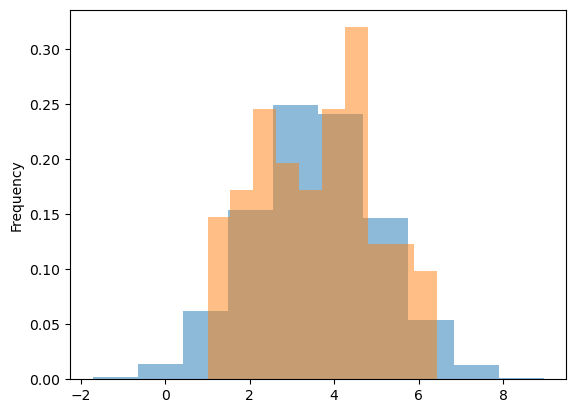

In [16]:
sample_df["x3"].plot.hist(alpha = 0.5, density = True)
df["x3"].plot.hist(alpha = 0.5, density = True)

In [83]:
import scipy.stats as stats
from graphlib import TopologicalSorter, _NodeInfo

class rv_sem2(_NodeInfo):
    def __init__(self, formula: str):

        if "<-" in formula:
            lhs, rhs = formula.replace(" ", "").split("<-")
            super().__init__(lhs) # lhs is the variable name
            self.predecessors = rhs.split("+") # rhs is the parents of the node
            self.dist = None
            self.is_random = False
        elif "~" in formula:
            lhs, rhs = formula.replace(" ", "").split("~")
            super().__init__(lhs) # lhs is the variable name
            self.predecessors = []
            self.is_random = True
            self.dist = eval("stats."+rhs+"()") # rhs is the distribution (must be a class in scipy.stats)
        else:
            raise ValueError("Formula does not contain <- or ~.")

        self.npredecessors = len(self.predecessors)
        self.formula = formula

    def __repr__(self):
        return self.formula

In [94]:
import torch
from torch import nn
class sem2(TopologicalSorter, nn.Module):
    def __init__(self, model_formula = None):

        super().__init__(graph = None)

        formula_list = model_formula.replace(" ", "").split(";")

        # Initialize node info by formula
        var = [rv_sem2(formula) for formula in formula_list]
        self._node2info = {v.node:v for v in var}                
        
        for node, v in self._node2info.items():                
            for p in v.predecessors:
                self._node2info[p].successors.append(node)

        self.layer = {}
        for node, v in self._node2info.items():
            if v.is_random is True:
                self.layer[node] = None
            else:
                self.layer[node] = nn.Linear(v.npredecessors, 1)
    
    def _get_nodeinfo(self, node: str):
        """Override original private method, raise an error if node does not exist
        """
        return self._node2info[node]

    def add(self, node, *predecessors):
        """Override original methods, don't do anything
        """
        return None

    def forward(self, batch_size = 1):
        x = torch.tensor([])
        for node in model.static_order():
            v = self._node2info[node]
            if v.is_random is True:
                new = v.rvs(batch_size) # this needs to be changed; needs to output a tensor
            else:
                x_pred = x[:,v.predecessors] # this definitely needs to be changed...
                new = self.layer[node](x_pred)
            x = torch.cat([x, new], dim = 1)
        return x

In [92]:
model_formula = "X <- A + B + C; B <- A + C; A ~ uniform; C ~ norm"
model = sem2(model_formula)
var = model._node2info
[var, 
 var["A"].dist.rvs(10), var["C"].dist.rvs(10), 
 var["A"].successors, var["B"].predecessors, var["B"].npredecessors, 
 tuple(model.static_order())]

[{'X': X<-A+B+C, 'B': B<-A+C, 'A': A~uniform, 'C': C~norm},
 array([0.78602459, 0.66834892, 0.17088513, 0.15277093, 0.28460008,
        0.30365225, 0.07804814, 0.10536583, 0.70371536, 0.17626422]),
 array([-1.61090712,  0.89869859,  0.19597543,  1.60411081,  1.81954762,
         0.15491168, -0.01045817,  1.65796741, -0.36246128, -0.94983206]),
 ['X', 'B'],
 ['A', 'C'],
 2,
 ('A', 'C', 'B', 'X')]